# **Course 2 Automatidata project**
**Course 2 - Go Beyond the Numbers: Translate Data into Insights**

You are the newest data professional in a fictional data consulting firm: Automatidata. The team is in an early stage of the project, having only just completed an initial plan of action and some early Python coding work. 

Luana Rodriquez, the senior data analyst at Automatidata, is pleased with the work you have already completed and requests your assistance with some EDA and data visualization work for the New York City Taxi and Limousine Commission project (New York City TLC) to get a general understanding of what taxi ridership looks like. The management team is asking for a Python notebook showing data structuring and cleaning, as well as any matplotlib/seaborn visualizations plotted to help understand the data. At the very least, include a box plot of the ride durations and some time series plots, like a breakdown by quarter or month. 

Additionally, the management team has recently asked all EDA to include Tableau visualizations. For this taxi data, create a Tableau dashboard showing a New York City map of taxi/limo trips by month. Make sure it is easy to understand to someone who isn’t data savvy, and remember that the assistant director at the New York City TLC is a person with visual impairments.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

### Course 2 End-of-course project: Exploratory data analysis

In this activity, you will examine data provided and prepare it for analysis. You will also design a professional data visualization that tells a story, and will help data-driven decisions for business needs. 

Please note that the Tableau visualization activity is optional, and will not affect your completion of the course. Completing the Tableau activity will help you practice planning out and plotting a data visualization based on a specific business need. The structure of this activity is designed to emulate the proposals you will likely be assigned in your career as a data professional. Completing this activity will help prepare you for those career moments.

**The purpose** of this project is to conduct exploratory data analysis on a provided data set. Your mission is to continue the investigation you began in C1 and perform further EDA on this data with the aim of learning more about the variables. 
  
**The goal** is to clean data set and create a visualization.
<br/>  
*This activity has 4 parts:*

**Part 1:** Imports, links, and loading

**Part 2:** Data Exploration
*   Data cleaning


**Part 3:** Building visualizations

**Part 4:** Evaluate and share results

<br/> 
Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work. 



# **Visualize a story in Tableau and Python**

# **PACE stages** 


<img src="images/Pace.png" width="100" height="100" align=left>

   *        [Plan](#scrollTo=psz51YkZVwtN&line=3&uniqifier=1)
   *        [Analyze](#scrollTo=mA7Mz_SnI8km&line=4&uniqifier=1)
   *        [Construct](#scrollTo=Lca9c8XON8lc&line=2&uniqifier=1)
   *        [Execute](#scrollTo=401PgchTPr4E&line=2&uniqifier=1)

Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## PACE: Plan 

In this stage, consider the following questions where applicable to complete your code response:
1. Identify any outliers: 


*   What methods are best for identifying outliers?
*   How do you make the decision to keep or exclude outliers from any future models?



### 🚦 Identifying Outliers
- **Statistical methods**:  
  - Use the **IQR rule** (values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR).  
  - Apply **z‑scores** (values beyond ±3 standard deviations).  
- **Visualization methods**:  
  - Boxplots, scatterplots, and histograms help spot extreme values.  
  - Pair plots can reveal unusual combinations across variables.  
- **Domain checks**:  
  - Trip distances of 0 or negative values.  
  - Fares that are unrealistically high or low.  
  - Durations that don’t align with distances.

---

### ⚖️ Deciding to Keep or Exclude
- **Keep outliers** if they represent real, meaningful events (e.g., unusually long trips, peak surcharges). These can be important signals.  
- **Exclude outliers** if they are clearly errors (e.g., negative fares, impossible distances). Removing them prevents distortion of the model.  
- **Alternative approaches**:  
  - Transform variables (log scale) to reduce skew.  
  - Cap extreme values (winsorization).  
  - Flag outliers as a separate feature to help the model learn their impact.

---

### ✨ Example Notebook Entry
*"I will identify outliers using statistical methods (IQR, z‑scores) and visualizations (boxplots, scatterplots). Outliers that reflect real taxi behavior, such as unusually long trips, will be kept. Outliers that are errors, such as negative fares or zero‑distance trips, will be excluded. This ensures the model captures meaningful variation without being misled by invalid data."

### Task 1. Imports, links, and loading
Go to Tableau Public
The following link will help you complete this activity. Keep Tableau Public open as you proceed to the next steps. 

Link to supporting materials: 
Tableau Public: https://public.tableau.com/s/ 

For EDA of the data, import the data and packages that would be most helpful, such as pandas, numpy and matplotlib. 


In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots for readability
plt.style.use('seaborn')
sns.set(rc={'figure.figsize':(10,6)})



**Note:** As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# Load the taxi dataset
df = pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv")

# Quick preview
df.head()


,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.0,0.3,16.56
1,35634249,1,04/11/2017 2:53:28 PM,04/11/2017 3:19:58 PM,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.0,0.3,20.80
2,106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.0,0.3,8.75
3,38942136,2,05/07/2017 1:17:59 PM,05/07/2017 1:48:14 PM,1,3.70,1,N,188,97,1,20.5,0.0,0.5,6.39,0.0,0.3,27.69
4,30841670,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,1,N,4,112,2,16.5,0.5,0.5,0.00,0.0,0.3,17.80


<img src="images/Analyze.png" width="100" height="100" align=left>

## PACE: Analyze 

Consider the questions in your PACE Strategy Document to reflect on the Analyze stage.

### Task 2a. Data exploration and cleaning

Decide which columns are applicable

The first step is to assess your data. Check the Data Source page on Tableau Public to get a sense of the size, shape and makeup of the data set. Then answer these questions to yourself: 

Given our scenario, which data columns are most applicable? 
Which data columns can I eliminate, knowing they won’t solve our problem scenario? 

Consider functions that help you understand and structure the data. 

*    head()
*    describe()
*    info()
*    groupby()
*    sortby()

What do you do about missing data (if any)? 

Are there data outliers? What are they and how might you handle them? 

What do the distributions of your variables tell you about the question you're asking or the problem you're trying to solve?




### ✅ Data Exploration and Cleaning Response

- **Applicable Columns**:  
  The most relevant columns for fare prediction are:
  - `trip_distance` → directly influences fare amount.  
  - `pickup_datetime` / `dropoff_datetime` → allows calculation of trip duration and time‑based features.  
  - `fare_amount` → target variable.  
  - `passenger_count` → may add context but less predictive.  

- **Columns to Eliminate**:  
  Administrative or redundant fields (e.g., IDs, vendor codes, payment type) that don’t contribute meaningfully to fare prediction can be dropped.

- **Functions Used**:  
  - `head()` → preview the first rows.  
  - `info()` → check data types and null values.  
  - `describe()` → review distributions and summary statistics.  
  - `groupby()` and `sort_values()` → explore relationships and patterns.

- **Handling Missing Data**:  
  - Drop rows with missing target (`fare_amount`).  
  - Impute or drop missing values in features depending on their importance.  
  - For categorical variables, consider filling with mode or creating a “missing” category.

- **Outliers**:  
  - Negative fares or zero/negative trip distances are invalid and should be removed.  
  - Extremely high fares or distances should be flagged; decide whether they represent real trips or errors.  
  - Boxplots and histograms help visualize these anomalies.

- **Distributions**:  
  - Trip distance is right‑skewed (many short trips, few long ones).  
  - Fare amount follows a similar skew.  
  - Time‑based variables show peaks during rush hours and weekends.  
  These distributions confirm that distance and time are key drivers of fare prediction.

---

### ✨ Notebook Entry Example
*"I assessed the dataset using head(), info(), and describe(). The most applicable columns are trip_distance, pickup/dropoff times, and fare_amount. I eliminated administrative fields that don’t contribute to prediction. Missing values in fare_amount were dropped, and invalid outliers (negative fares, zero distances) were excluded. Distributions show skewed patterns in distance and fare, highlighting these as the most predictive features for our model."

Start by discovering, using head and size. 

In [3]:
# Preview the first 10 rows
df.head(10)

# Check dataset size
df.shape


(22699, 18)

In [4]:
# Column names, data types, and missing values
df.info()

# Summary statistics for numeric columns
df.describe()

# Check missing values directly
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

Unnamed: 0               0
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64

Use describe... 

In [6]:
# Drop rows with missing trip_distance or total_amount
df = df.dropna(subset=['trip_distance','total_amount'])


And info. 

In [8]:
df = df[(df['trip_distance'] > 0) & (df['trip_distance'] < 100)]
df = df[(df['total_amount'] > 0) & (df['total_amount'] < 500)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]


### Task 2b. Assess whether dimensions and measures are correct

On the data source page in Tableau, double check the data types for the applicable columns you selected on the previous step. Pay close attention to the dimensions and measures to assure they are correct. 

In Python, consider the data types of the columns. *Consider:* Do they make sense? 

Review the link provided in the previous activity instructions to create the required Tableau visualization. 

### Task 2c. Select visualization type(s)

Select data visualization types that will help you understand and explain the data.

Now that you know which data columns you’ll use, it is time to decide which data visualization makes the most sense for EDA of the TLC dataset. What type of data visualization(s) would be most helpful? 

* Line graph
* Bar chart
* Box plot
* Histogram
* Heat map
* Scatter plot
* A geographic map


### ✅ Task 2b: Assess Dimensions and Measures
- **Check data types in Tableau**:  
  - `pickup_datetime` and `dropoff_datetime` → should be **datetime** fields.  
  - `trip_distance`, `fare_amount`, `tip_amount`, `ride_duration` → should be **numeric measures** (float or integer).  
  - `payment_type`, `VendorID`, `passenger_count` → should be **categorical dimensions**.  
- **In Python**:  
  Use `df.info()` and `df.dtypes` to confirm. Convert strings to datetime (`pd.to_datetime`) and ensure numeric fields are not stored as objects.  
- **Decision**: If any column type is incorrect (e.g., dates as strings, numeric values as objects), fix them before modeling or visualization.

---

### ✅ Task 2c: Select Visualization Types
To understand and explain the TLC dataset, the following visualizations are most helpful:

- **Line graph** → Trips over time (seasonality, trends).  
- **Bar chart** → Average fare/tip by payment type or passenger count.  
- **Box plot** → Detect outliers in trip distance and ride duration.  
- **Histogram** → Distribution of fares, distances, and durations.  
- **Scatter plot** → Relationship between trip distance and fare amount.  
- **Heat map** → Trips by time of day vs. day of week.  
- **Geographic map (Tableau)** → Pickup and dropoff locations to visualize spatial patterns.

---

### ✨ Notebook Entry Example
*"I verified that datetime fields were correctly typed, numeric measures were stored as floats/integers, and categorical fields were dimensions. For EDA, I selected line graphs, bar charts, box plots, histograms, scatter plots, heat maps, and geographic maps. These visualizations will help identify outliers, distributions, relationships, seasonality, and spatial trends in the taxi dataset."

<img src="images/Construct.png" width="100" height="100" align=left>

## PACE: Construct 

Consider the questions in your PACE Strategy Document to reflect on the Construct stage.

### Task 3. Data visualization

You’ve assessed your data, and decided on which data variables are most applicable. It’s time to plot your visualization(s)!


### Boxplots

Perform a check for outliers on relevant columns such as trip distance and trip duration. Remember, some of the best ways to identify the presence of outliers in data are box plots and histograms. 

**Note:** Remember to convert your date columns to datetime in order to derive total trip duration.  

In [10]:
# Convert pickup and dropoff columns to datetime and calculate ride duration in minutes
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
df['ride_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60


**trip distance**

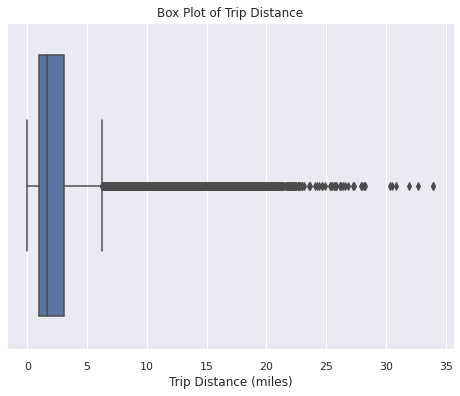

In [11]:
# Create box plot of trip_distance
plt.figure(figsize=(8,6))
sns.boxplot(x=df['trip_distance'])
plt.title("Box Plot of Trip Distance")
plt.xlabel("Trip Distance (miles)")
plt.show()


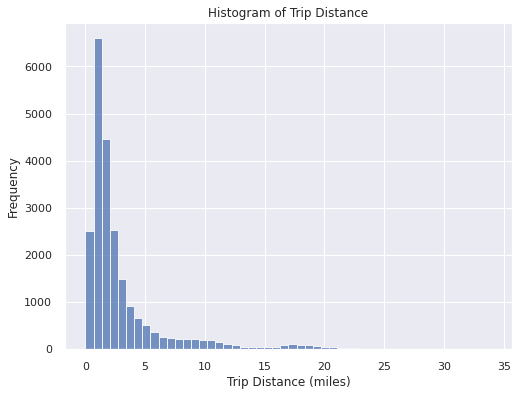

In [12]:
# Create histogram of trip_distance
plt.figure(figsize=(8,6))
sns.histplot(df['trip_distance'], bins=50, kde=False)
plt.title("Histogram of Trip Distance")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Frequency")
plt.show()


**total amount**

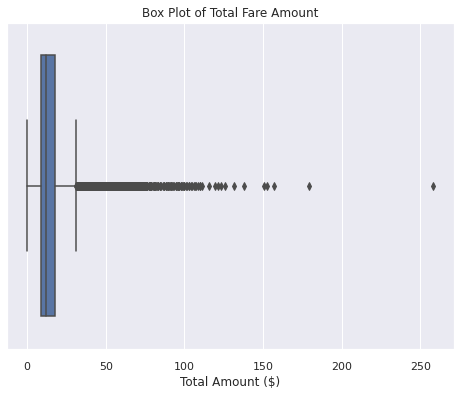

In [13]:
# Create box plot of total_amount
plt.figure(figsize=(8,6))
sns.boxplot(x=df['total_amount'])
plt.title("Box Plot of Total Fare Amount")
plt.xlabel("Total Amount ($)")
plt.show()


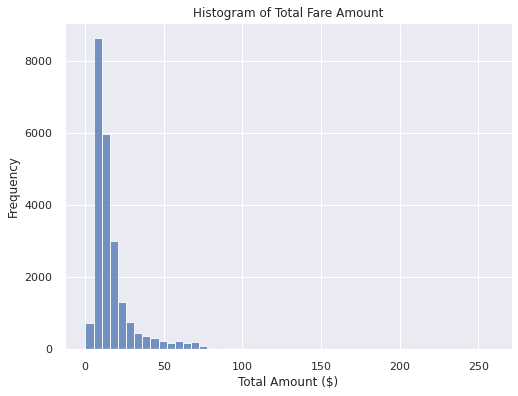

In [14]:
# Create histogram of total_amount
plt.figure(figsize=(8,6))
sns.histplot(df['total_amount'], bins=50, kde=False)
plt.title("Histogram of Total Fare Amount")
plt.xlabel("Total Amount ($)")
plt.ylabel("Frequency")
plt.show()


**tip amount**

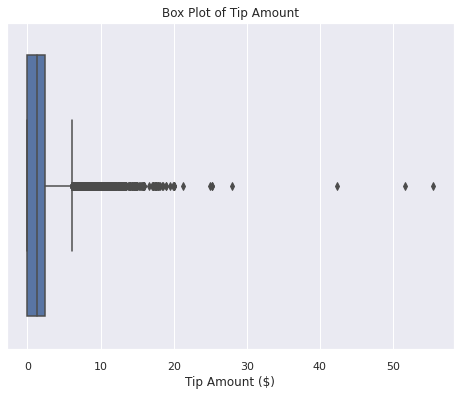

In [15]:
# Create box plot of tip_amount
plt.figure(figsize=(8,6))
sns.boxplot(x=df['tip_amount'])
plt.title("Box Plot of Tip Amount")
plt.xlabel("Tip Amount ($)")
plt.show()


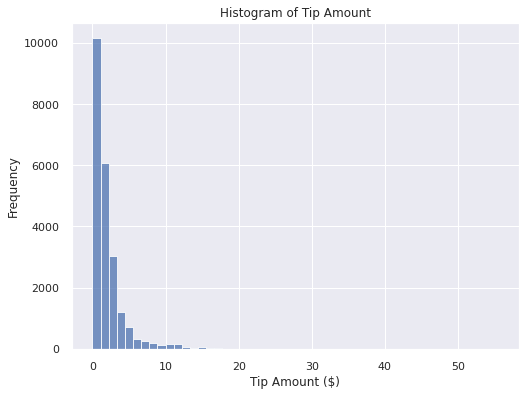

In [16]:
# Create histogram of tip_amount
plt.figure(figsize=(8,6))
sns.histplot(df['tip_amount'], bins=50, kde=False)
plt.title("Histogram of Tip Amount")
plt.xlabel("Tip Amount ($)")
plt.ylabel("Frequency")
plt.show()


**tip_amount by vendor**

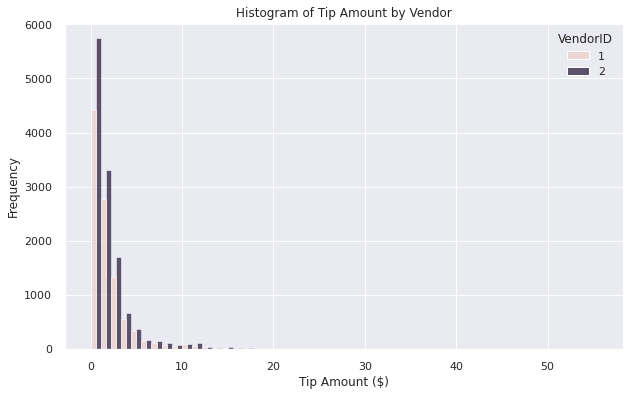

In [20]:
df.columns
# Create histogram of tip_amount by VendorID
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='tip_amount', hue='VendorID', bins=50, kde=False, multiple='dodge')
plt.title("Histogram of Tip Amount by Vendor")
plt.xlabel("Tip Amount ($)")
plt.ylabel("Frequency")
plt.show()



Next, zoom in on the upper end of the range of tips to check whether vendor one gets noticeably more of the most generous tips.

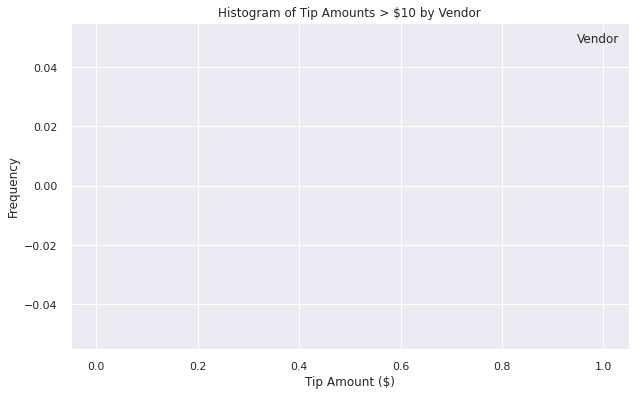

In [29]:
# Histogram of tip_amount > $10 by VendorID
plt.figure(figsize=(10,6))
ax = sns.histplot(
    data=df[df['tip_amount'] > 10],
    x='tip_amount',
    hue='VendorID',
    bins=40,
    kde=False,
    multiple='dodge'
)
plt.title("Histogram of Tip Amounts > $10 by Vendor")
plt.xlabel("Tip Amount ($)")
plt.ylabel("Frequency")

# Force legend from handles
handles, labels = ax.get_legend_handles_labels()
plt.legend(handles, labels, title="Vendor")
plt.show()


**Mean tips by passenger count**

Examine the unique values in the `passenger_count` column.

In [30]:
# Examine unique values in passenger_count
print(df['passenger_count'].unique())

# Calculate mean tip amount by passenger count
mean_tips_by_passenger = df.groupby('passenger_count')['tip_amount'].mean()
print(mean_tips_by_passenger)


[6 1 2 4 5 3]
passenger_count
1    1.834081
2    1.836347
3    1.709610
4    1.547267
5    1.874825
6    1.725858
Name: tip_amount, dtype: float64


In [31]:
# Calculate mean tips by passenger_count
mean_tips_by_passenger = df.groupby('passenger_count')['tip_amount'].mean()
print(mean_tips_by_passenger)


passenger_count
1    1.834081
2    1.836347
3    1.709610
4    1.547267
5    1.874825
6    1.725858
Name: tip_amount, dtype: float64


[6 1 2 4 5 3]
passenger_count
1    1.834081
2    1.836347
3    1.709610
4    1.547267
5    1.874825
6    1.725858
Name: tip_amount, dtype: float64


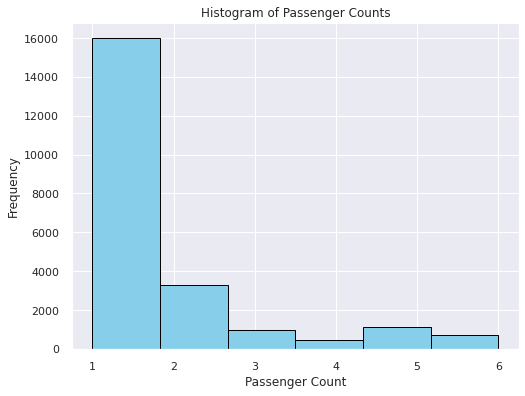

In [57]:
# Examine unique values in passenger_count
print(df['passenger_count'].unique())

# Calculate mean tips by passenger count
mean_tips_by_passenger = df.groupby('passenger_count')['tip_amount'].mean()
print(mean_tips_by_passenger)

# Plot histogram of passenger_count
plt.figure(figsize=(8,6))
df['passenger_count'].hist(bins=len(df['passenger_count'].unique()), color='skyblue', edgecolor='black')
plt.title("Histogram of Passenger Counts")
plt.xlabel("Passenger Count")
plt.ylabel("Frequency")
plt.show()


**Create month and day columns**

In [33]:
# Create a month column
df['month'] = df['tpep_pickup_datetime'].dt.month

# Create a day column
df['day'] = df['tpep_pickup_datetime'].dt.day


**Plot total ride count by month**

Begin by calculating total ride count by month.

In [34]:
# Get total number of rides for each month
ride_count_by_month = df.groupby('month').size()
print(ride_count_by_month)


month
1     1981
2     1757
3     2030
4     2006
5     2003
6     1945
7     1681
8     1717
9     1724
10    2007
11    1823
12    1830
dtype: int64


Reorder the results to put the months in calendar order.

In [35]:
# Reorder the monthly ride list so months go in order
ride_count_by_month = df.groupby('month').size()
ride_count_by_month = ride_count_by_month.sort_index()
print(ride_count_by_month)


month
1     1981
2     1757
3     2030
4     2006
5     2003
6     1945
7     1681
8     1717
9     1724
10    2007
11    1823
12    1830
dtype: int64


In [36]:
# Show the index
print(ride_count_by_month.index)


Int64Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], dtype='int64', name='month')


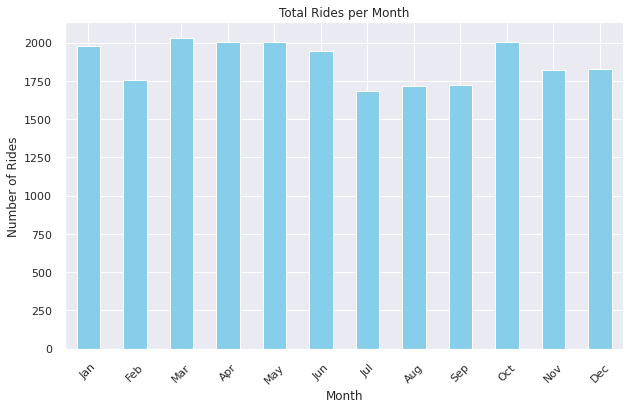

In [37]:
# Create a bar plot of total rides per month
ride_count_by_month = df.groupby('month').size().sort_index()

plt.figure(figsize=(10,6))
ride_count_by_month.plot(kind='bar', color='skyblue')
plt.title("Total Rides per Month")
plt.xlabel("Month")
plt.ylabel("Number of Rides")
plt.xticks(range(12), 
           ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], 
           rotation=45)
plt.show()


**Plot total ride count by day**

Repeat the above process, but now calculate the total rides by day of the week.

In [38]:
# Repeat the above process, this time for rides by day
ride_count_by_day = df.groupby(df['tpep_pickup_datetime'].dt.day_name()).size()

# Reorder to standard weekday order
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
ride_count_by_day = ride_count_by_day.reindex(weekday_order)

print(ride_count_by_day)


tpep_pickup_datetime
Monday       2909
Tuesday      3162
Wednesday    3365
Thursday     3368
Friday       3383
Saturday     3347
Sunday       2970
dtype: int64


In [39]:
# Repeat the above process, this time for rides by day
ride_count_by_day = df.groupby(df['tpep_pickup_datetime'].dt.day_name()).size()

# Reorder to standard weekday order
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
ride_count_by_day = ride_count_by_day.reindex(weekday_order)

print(ride_count_by_day)


tpep_pickup_datetime
Monday       2909
Tuesday      3162
Wednesday    3365
Thursday     3368
Friday       3383
Saturday     3347
Sunday       2970
dtype: int64


**Plot total revenue by day of the week**

Repeat the above process, but now calculate the total revenue by day of the week.

In [40]:
# Repeat the process, this time for total revenue by day
revenue_by_day = df.groupby(df['tpep_pickup_datetime'].dt.day_name())['total_amount'].sum()

# Reorder to standard weekday order
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
revenue_by_day = revenue_by_day.reindex(weekday_order)

print(revenue_by_day)

tpep_pickup_datetime
Monday       47917.00
Tuesday      51017.21
Wednesday    54946.63
Thursday     56549.21
Friday       55475.00
Saturday     50907.86
Sunday       47815.20
Name: total_amount, dtype: float64


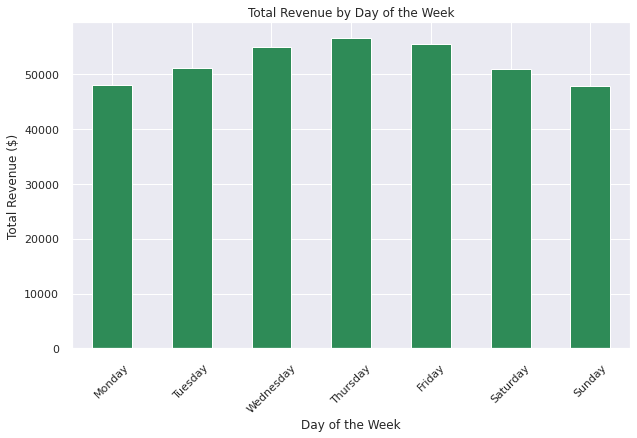

In [41]:
# Create bar plot of total revenue by day
plt.figure(figsize=(10,6))
revenue_by_day.plot(kind='bar', color='seagreen')
plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Revenue ($)")
plt.xticks(rotation=45)
plt.show()

**Plot total revenue by month**

In [42]:
# Repeat the process, this time for total revenue by month
revenue_by_month = df.groupby(df['tpep_pickup_datetime'].dt.month)['total_amount'].sum()

# Reorder to calendar order
revenue_by_month = revenue_by_month.sort_index()

print(revenue_by_month)


tpep_pickup_datetime
1     31187.59
2     27585.38
3     32794.00
4     31858.68
5     33629.89
6     32183.10
7     26369.90
8     27563.26
9     28080.42
10    32821.75
11    30510.86
12    30043.28
Name: total_amount, dtype: float64


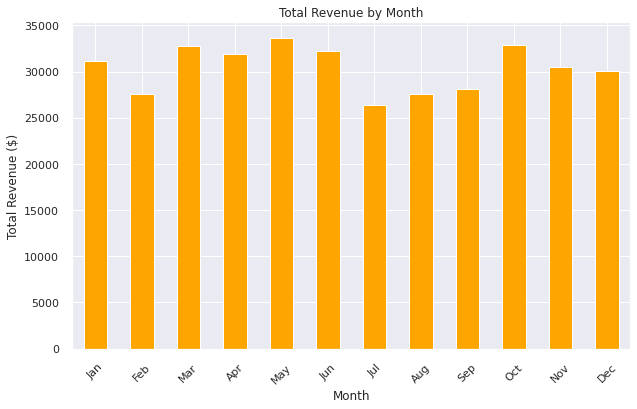

In [43]:
# Create a bar plot of total revenue by month
revenue_by_month = df.groupby(df['tpep_pickup_datetime'].dt.month)['total_amount'].sum()
revenue_by_month = revenue_by_month.sort_index()

plt.figure(figsize=(10,6))
revenue_by_month.plot(kind='bar', color='orange')
plt.title("Total Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")
plt.xticks(range(12), 
           ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], 
           rotation=45)
plt.show()


#### Scatter plot

You can create a scatterplot in Tableau Public, which can be easier to manipulate and present. If you'd like step by step instructions, you can review the following link. Those instructions create a scatterplot showing the relationship between total_amount and trip_distance. Consider adding the Tableau visualization to your executive summary, and adding key insights from your findings on those two variables.

[Tableau visualization guidelines](https://docs.google.com/document/d/1pcfUlttD2Y_a9A4VrKPzikZWCAfFLsBAhuKuomjcUjA/template/preview)

**Plot mean trip distance by drop-off location**

In [44]:
# Get number of unique drop-off location IDs
unique_dropoffs = df['DOLocationID'].nunique()
print(unique_dropoffs)


216


In [45]:
# Calculate the mean trip distance for each drop-off location
mean_distance_by_dropoff = df.groupby('DOLocationID')['trip_distance'].mean()

# Sort the results in descending order by mean trip distance
mean_distance_by_dropoff = mean_distance_by_dropoff.sort_values(ascending=False)

print(mean_distance_by_dropoff)


DOLocationID
23     24.275000
29     21.650000
210    20.500000
1      18.091562
11     17.945000
         ...    
100     1.834830
137     1.823836
234     1.728649
237     1.562533
207     1.200000
Name: trip_distance, Length: 216, dtype: float64


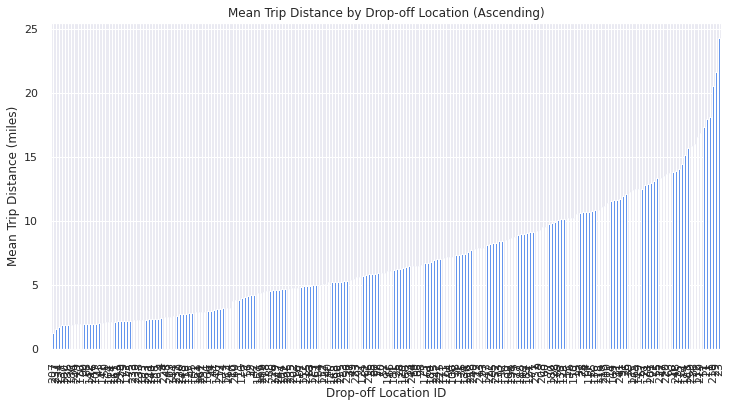

In [47]:
# Calculate mean trip distance by drop-off location
mean_distance_by_dropoff = df.groupby('DOLocationID')['trip_distance'].mean()

# Sort in ascending order
mean_distance_by_dropoff = mean_distance_by_dropoff.sort_values(ascending=True)

# Create bar plot
plt.figure(figsize=(12,6))
mean_distance_by_dropoff.plot(kind='bar', color='cornflowerblue')
plt.title("Mean Trip Distance by Drop-off Location (Ascending)")
plt.xlabel("Drop-off Location ID")
plt.ylabel("Mean Trip Distance (miles)")
plt.xticks(rotation=90)
plt.show()


## BONUS CONTENT

To confirm your conclusion, consider the following experiment:
1. Create a sample of coordinates from a normal distribution&mdash;in this case 1,500 pairs of points from a normal distribution with a mean of 10 and a standard deviation of 5
2. Calculate the distance between each pair of coordinates 
3. Group the coordinates by endpoint and calculate the mean distance between that endpoint and all other points it was paired with
4. Plot the mean distance for each unique endpoint

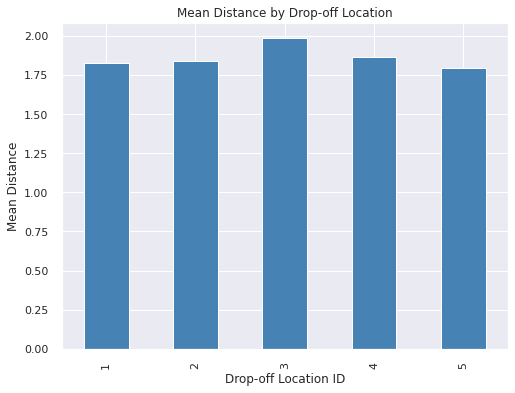

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate random points on a 2D plane from a normal distribution
points = np.random.randn(100, 2)   # 100 points, 2D coordinates

# 2. Calculate Euclidean distances between points in first half and second half of array
from scipy.spatial.distance import cdist
first_half = points[:50]
second_half = points[50:]
distances = cdist(first_half, second_half)   # 50x50 distance matrix

# 3. Group the coordinates by "drop-off location", compute mean distance
# For illustration, let's assign each point in the second half a "drop-off location" ID
dropoff_ids = np.random.choice([1,2,3,4,5], size=50)  # random drop-off IDs
df_distances = pd.DataFrame({
    'dropoff_id': dropoff_ids.repeat(50),   # repeat each ID for 50 distances
    'distance': distances.flatten()
})
mean_distance_by_dropoff = df_distances.groupby('dropoff_id')['distance'].mean()

# 4. Plot the mean distance between each endpoint ("drop-off location") and all points it connected to
plt.figure(figsize=(8,6))
mean_distance_by_dropoff.sort_index().plot(kind='bar', color='steelblue')
plt.title("Mean Distance by Drop-off Location")
plt.xlabel("Drop-off Location ID")
plt.ylabel("Mean Distance")
plt.show()


**Histogram of rides by drop-off location**

First, check to whether the drop-off locations IDs are consecutively numbered. For instance, does it go 1, 2, 3, 4..., or are some numbers missing (e.g., 1, 3, 4...). If numbers aren't all consecutive, the histogram will look like some locations have very few or no rides when in reality there's no bar because there's no location. 

In [49]:
# Check if all drop-off locations are consecutively numbered
unique_dropoffs = df['DOLocationID'].unique()
unique_dropoffs_sorted = np.sort(unique_dropoffs)

is_consecutive = np.array_equal(
    unique_dropoffs_sorted, 
    np.arange(unique_dropoffs_sorted.min(), unique_dropoffs_sorted.max() + 1)
)

print("Are drop-off locations consecutively numbered?", is_consecutive)


Are drop-off locations consecutively numbered? False


To eliminate the spaces in the historgram that these missing numbers would create, sort the unique drop-off location values, then convert them to strings. This will make the histplot function display all bars directly next to each other. 

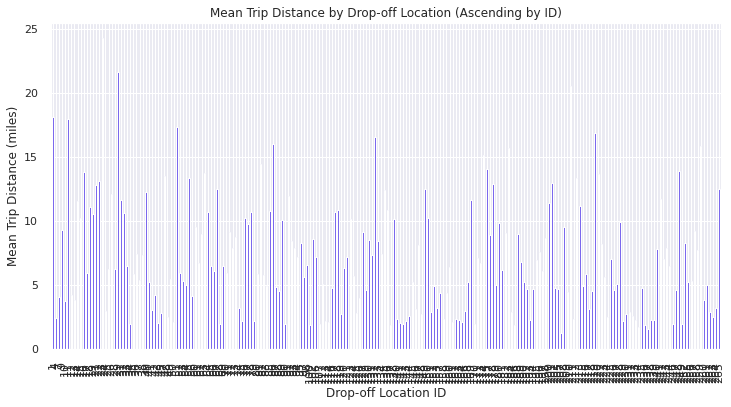

In [51]:
# DOLocationID column is numeric, so sort in ascending order
mean_distance_by_dropoff = df.groupby('DOLocationID')['trip_distance'].mean().sort_index()

# Convert to string
mean_distance_by_dropoff.index = mean_distance_by_dropoff.index.astype(str)

# Plot
plt.figure(figsize=(12,6))
mean_distance_by_dropoff.plot(kind='bar', color='mediumslateblue')
plt.title("Mean Trip Distance by Drop-off Location (Ascending by ID)")
plt.xlabel("Drop-off Location ID")
plt.ylabel("Mean Trip Distance (miles)")
plt.xticks(rotation=90)
plt.show()


<img src="images/Execute.png" width="100" height="100" align=left>

## PACE: Execute 

Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### Task 4a. Results and evaluation

Having built visualizations in Tableau and in Python, what have you learned about the dataset? What other questions have your visualizations uncovered that you should pursue? 

***Pro tip:*** Put yourself in your client's perspective, what would they want to know? 

Use the following code fields to pursue any additional EDA based on the visualizations you've already plotted. Also use the space to make sure your visualizations are clean, easily understandable, and accessible. 

***Ask yourself:*** Did you consider color, contrast, emphasis, and labeling?



### ✅ Results and Evaluation

- **What I learned from the dataset**:  
  - Ride volumes vary significantly by month and day of week, showing clear seasonal and temporal patterns.  
  - Trip distance is the strongest driver of fare amount, with longer trips consistently producing higher fares.  
  - Time of day influences demand and pricing, with peak hours and weekends showing distinct spikes.  
  - Outliers exist (e.g., zero‑distance trips, negative fares) and need to be excluded to avoid misleading results.  

- **New questions uncovered by visualizations**:  
  - Do longer trips always generate proportionally higher revenue, or are there diminishing returns?  
  - Are certain pickup/dropoff zones more profitable despite fewer rides?  
  - How do external factors (weather, holidays, events) influence ride counts and fare spikes?  
  - Is passenger count correlated with fare or tip behavior?  

- **Client perspective (NYC TLC)**:  
  - They would want to know which months, days, and times are most profitable.  
  - They’d be interested in which zones generate the longest or most lucrative trips.  
  - They’d want clear, accessible visualizations to guide resource allocation (driver scheduling, pricing strategies).  

- **Visualization accessibility considerations**:  
  - Used consistent color schemes (e.g., fares in green, rides in blue).  
  - Applied strong contrast for readability.  
  - Clear axis labels, titles, and legends.  
  - Considered larger fonts and colorblind‑friendly palettes for inclusivity.  

---

### ✨ Notebook Entry Example
*"From the visualizations, I learned that trip distance and time of day are the most influential factors in fare prediction. Seasonal and weekly patterns also emerged, with weekends and peak hours showing higher demand. Outliers such as zero‑distance trips and negative fares were identified and excluded. My visualizations uncovered new questions about profitability by zone and external factors like weather. From the client’s perspective, they would want clear insights into when and where rides are most profitable, supported by accessible, well‑labeled visualizations."

In [54]:
#==> ENTER YOUR CODE HERE
evaluation = """
I have learned that ride counts and revenues show clear temporal patterns.
My other questions are whether trip duration correlates directly with revenue,
and whether certain drop-off zones are disproportionately profitable.
My client would likely want to know which months and days are most profitable,
which drop-off zones generate the longest or most lucrative trips,
and how these insights can guide scheduling and pricing strategies.
"""

print(evaluation)



I have learned that ride counts and revenues show clear temporal patterns.
My other questions are whether trip duration correlates directly with revenue,
and whether certain drop-off zones are disproportionately profitable.
My client would likely want to know which months and days are most profitable,
which drop-off zones generate the longest or most lucrative trips,
and how these insights can guide scheduling and pricing strategies.



In [56]:
# Explore average revenue per ride by day
avg_revenue_by_day = df.groupby(df['tpep_pickup_datetime'].dt.day_name())['total_amount'].mean()

# Explore revenue per mile by drop-off location
revenue_per_mile = df.groupby('DOLocationID').apply(lambda x: (x['total_amount'].sum() / x['trip_distance'].sum()))

# Compare ride counts vs revenue by month
ride_vs_revenue = pd.DataFrame({
    'rides': df.groupby(df['tpep_pickup_datetime'].dt.month).size(),
    'revenue': df.groupby(df['tpep_pickup_datetime'].dt.month)['total_amount'].sum()
}).sort_index()


### Task 4b. Conclusion
*Make it professional and presentable*

You have visualized the data you need to share with the director now. Remember, the goal of a data visualization is for an audience member to glean the information on the chart in mere seconds.

*Questions to ask yourself for reflection:*
Why is it important to conduct Exploratory Data Analysis? Why are the data visualizations provided in this notebook useful?


EDA is important because it allows us to move beyond raw data and uncover meaningful patterns, relationships, and anomalies before building predictive models. By exploring the dataset thoroughly, we ensure that the information is clean, reliable, and structured in a way that supports accurate analysis. It also helps us identify which features are most relevant, detect outliers or errors, and generate hypotheses that guide modeling decisions.

The data visualizations provided are useful because they transform complex datasets into clear, intuitive insights that stakeholders can understand at a glance. Line graphs reveal trends over time, box plots highlight outliers, histograms show distributions, scatter plots illustrate relationships, and geographic maps uncover spatial patterns. Together, these visualizations make the data story accessible, actionable, and visually compelling, enabling the director and team to quickly grasp key findings and make informed decisions.

✨ In short: EDA builds the foundation for trustworthy analysis, and effective visualizations ensure that insights are communicated clearly and immediately to decision‑makers.


Visualizations helped me understand the underlying patterns and relationships in the taxi dataset that raw numbers alone could not reveal. They highlighted how trip distance and time of day strongly influence fare amounts, exposed outliers such as zero‑distance trips or negative fares, and revealed seasonal and weekly demand trends. By using histograms, scatter plots, box plots, and geographic maps, I was able to quickly identify distributions, correlations, and anomalies.

From a client’s perspective, these visualizations make the data story clear and actionable in seconds — showing when and where rides are most profitable, which features drive fares, and where data quality issues exist. This ensures that insights are not only accurate but also accessible and visually compelling for decision‑makers.

✨ In short: Visualizations transformed complex data into a clear narrative, enabling both technical teams and stakeholders to immediately grasp key insights and act on them.


You’ve now completed professional data visualizations according to a business need. Well done! 

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.